# Homework 1 — Variational Autoencoder for Chest X-ray Image Generation

**ECE 285 — Homework 1**

| Item | Value |
|---|---|
| Name | *<fill in>* |
| Student ID | *<fill in>* |
| Conda environment | `ml` (`conda activate ml`) |
| Dataset | [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia) |

This notebook implements a **Variational Autoencoder (VAE)** [Kingma & Welling, 2014] in PyTorch, trains it on the
Kaggle chest X-ray dataset and uses it to synthesise new chest X-ray images. The generated images are evaluated with the
**Inception Score (IS)** and the **Frechet Inception Distance (FID)** using `pytorch-ignite`, following the reference
notebook *GAN evaluation using FID and IS* (<https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/>).

## Contents

1. **Setup** — environment, reproducibility, single configuration object
2. **Data** — splits, transforms, dataloaders, quick EDA
3. **Model** — encoder / decoder / VAE, ELBO objective
4. **Metrics** — IS + FID evaluation engine
5. **Training** — optimiser, schedules, engine handlers
6. **Results** — loss curves, IS/FID curves
7. **Generated images** — random samples, latent interpolation, reconstructions
8. **Reference metrics** — IS of real images, FID between two halves of the real set
9. **Export for the report** — CSV/JSON/figures + limitations

## References

- Kingma & Welling, *Auto-Encoding Variational Bayes*, ICLR 2014.
- Heusel et al., *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium*, NeurIPS 2017 (FID).
- Barratt & Sharma, *A Note on the Inception Score*, 2018.
- PyTorch-Ignite blog, *GAN evaluation using FID and IS*.
- Parmar et al., *On Aliased Resizing and Surprising Subtleties in GAN Evaluation*, CVPR 2022.


## 1. Setup

### 1.1 Environment

Every cell below is written for the **`ml`** conda environment:

```bash
conda activate ml
pip install pytorch-ignite      # the only extra dependency
```

`torch`, `torchvision`, `numpy`, `pandas`, `matplotlib`, `Pillow` and `tqdm` are already present in `ml`. Make sure the
kernel selected for this notebook is the one that points at `/opt/anaconda3/envs/ml/bin/python`; the first code cell
prints `sys.executable` so the environment can be verified at a glance.

### 1.2 Imports


In [2]:
import itertools
import json
import math
import os
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import torchvision.utils as vutils
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder

import ignite
from ignite.engine import Engine, Events
from ignite.handlers import ProgressBar
from ignite.metrics import FID, InceptionScore, RunningAverage
from ignite.metrics.gan.utils import InceptionModel

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "image.cmap": "gray",
        "font.size": 9,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)

print(f"python      : {sys.version.split()[0]}  ({sys.executable})")
print(f"torch       : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"ignite      : {ignite.__version__}")
print(f"numpy       : {np.__version__}")


python      : 3.11.11  (/opt/anaconda3/envs/ml/bin/python)
torch       : 2.13.0
torchvision : 0.28.0
ignite      : 0.5.5
numpy       : 2.1.3


### 1.3 Configuration

All hyperparameters live in a single dataclass so that (i) the notebook and the report can never disagree and (ii) the
whole setup is stored inside every checkpoint. The table printed below is exactly the *hyper-parameter setting* table of
the report.

- `image_size = 64` follows the reference GAN/VAE evaluation setup, which keeps the model small enough to train a
  meaningful number of epochs on a single accelerator. Raising it to `128` only requires changing this one field: the
  convolutional stacks are derived from `log2(image_size)`.
- `device = "mps"` uses the Apple Silicon GPU. The resolver falls back to CPU with an explicit warning if MPS is not
  available, so a silent 10× slowdown is impossible; use `"auto"` for `cuda → mps → cpu`.
- `eval_every = 5` keeps the (CPU-bound) Inception evaluation affordable: FID/IS is computed 11 times over the run
  instead of 25. Lower it to `2` if you want a denser curve and have the budget.


In [3]:
@dataclass
class Config:
    # ----- data -----
    data_root: str = "chest_xray"
    image_size: int = 64
    batch_size: int = 64
    num_workers: int = 2
    val_fraction: float = 0.10

    # ----- model -----
    in_channels: int = 1
    base_channels: int = 32
    latent_dim: int = 128

    # ----- optimisation -----
    epochs: int = 50
    lr: float = 1e-3
    lr_min: float = 1e-5
    weight_decay: float = 0.0
    beta: float = 1.0                # final KL weight (beta-VAE)
    kl_warmup_epochs: int = 10       # linear 0 -> beta ramp
    grad_clip: float = 5.0

    # ----- evaluation -----
    eval_num_images: int = 512       # real reference images for FID / IS
    eval_batch_size: int = 32
    eval_every: int = 5              # epochs between FID/IS evaluations
    fid_num_features: int = 2048     # InceptionV3 pool features
    sample_every: int = 5            # epochs between saved sample grids

    # ----- hardware -----
    device: str = "mps"              # "mps" | "cuda" | "cpu" | "auto"  (auto = cuda -> mps -> cpu)
    metric_device: str = "auto"      # FID/IS statistics need float64 -> cpu unless cuda is present

    # ----- bookkeeping -----
    seed: int = 42
    out_dir: str = "results"
    ckpt_dir: str = "checkpoints"


cfg = Config()

OUT_DIR = Path(cfg.out_dir)
FIG_DIR = OUT_DIR / "figures"
SAMPLE_DIR = OUT_DIR / "samples"
for d in (OUT_DIR, FIG_DIR, SAMPLE_DIR):
    d.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name: str, dpi: int = 150) -> Path:
    """Save a matplotlib figure into results/figures and return the path."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"saved figure -> {path}")
    return path


pd.DataFrame({"hyperparameter": list(asdict(cfg).keys()), "value": list(asdict(cfg).values())})


,hyperparameter,value
0,data_root,chest_xray
1,image_size,64
2,batch_size,64
3,num_workers,2
4,val_fraction,0.1
5,in_channels,1
6,base_channels,32
7,latent_dim,128
8,epochs,50
9,lr,0.001


### 1.4 Reproducibility and device (with MPS acceleration)

**Seeding.** One seed is fixed for Python, NumPy and PyTorch. `torch.use_deterministic_algorithms` is deliberately *not*
enabled: not every MPS/cuDNN kernel has a deterministic implementation, and the run-to-run variation of the metrics is far
smaller than the effect of any hyperparameter being varied.

**Device.** `pick_device()` resolves the requested device string:

| request | resolution |
|---|---|
| `"auto"` | CUDA → MPS → CPU (first available) |
| `"mps"` | Apple Silicon GPU; falls back to CPU with a warning if unavailable |
| `"cuda"` | CUDA; falls back to CPU with a warning if unavailable |
| `"cpu"` | always CPU |

**MPS specifics.** Four things matter on Apple Silicon and are all handled below:

1. `PYTORCH_ENABLE_MPS_FALLBACK=1` — a few ops have no MPS kernel. With the fallback enabled those ops silently run on
   CPU instead of raising, which is the difference between "slow" and "broken".
2. **`float64` is not supported on MPS.** `pytorch-ignite`'s `FID`/`InceptionScore` accumulate their statistics in
   `float64`, so the metrics must live on CPU (or CUDA). The expensive part — the InceptionV3 forward pass on 299×299
   inputs — still runs on the accelerator (`EXTRACTOR_DEVICE`, probed in §4), and only the resulting `(N, 2048)` matrix
   is copied to the metric device.
3. **`num_workers > 0` + MPS.** Forked workers inherit the MPS context and can deadlock. If the first batch ever hangs,
   set `Config.num_workers = 0`.
4. **Allocator growth.** `torch.mps.empty_cache()` is called after each sample-grid / evaluation to keep memory flat over
   50 epochs.

The resolved devices are printed below, and a three-iteration benchmark of the real architecture gives the expected run
time in §3.4 — so you know the duration *before* committing to the full training cell.


In [4]:
SEED = cfg.seed

# Must be set before the first MPS kernel is dispatched.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")


def seed_everything(seed: int = SEED) -> None:
    """Seed every RNG that the training pipeline touches."""
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def resolve_device(request: str = "auto") -> torch.device:
    """Resolve 'auto' | 'cuda' | 'mps' | 'cpu' to a torch.device, with graceful fallback."""
    has_cuda = torch.cuda.is_available()
    has_mps = getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available()

    if request == "auto":
        if has_cuda:
            return torch.device("cuda")
        if has_mps:
            return torch.device("mps")
        return torch.device("cpu")

    request = request.lower()
    if request == "cuda" and not has_cuda:
        print("warning: cuda requested but not available -> falling back to cpu")
        return torch.device("cpu")
    if request == "mps" and not has_mps:
        print("warning: mps requested but not available -> falling back to cpu")
        return torch.device("cpu")
    if request not in {"cuda", "mps", "cpu"}:
        raise ValueError(f"unknown device {request!r}; expected 'auto', 'cuda', 'mps' or 'cpu'")
    return torch.device(request)


seed_everything(SEED)

DEVICE = resolve_device(cfg.device)
if cfg.metric_device == "auto":
    # float64 is unsupported on MPS, so the Inception metrics prefer CUDA and otherwise run on CPU.
    METRIC_DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
else:
    METRIC_DEVICE = resolve_device(cfg.metric_device)

if DEVICE.type == "mps":
    # keeps the MPS allocator from growing unboundedly across the 50 epochs
    torch.mps.empty_cache()

print(f"python           : {sys.version.split()[0]}")
print(f"training device  : {DEVICE}   (mps built={getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_built()}, "
      f"mps available={getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available()}, "
      f"cuda available={torch.cuda.is_available()})")
print(f"metric device    : {METRIC_DEVICE}   (FID/IS need float64, which MPS does not support)")
print(f"MPS CPU fallback : {os.environ.get('PYTORCH_ENABLE_MPS_FALLBACK', '0')}")
print(f"torch threads    : {torch.get_num_threads()}")


python           : 3.11.11
training device  : mps   (mps built=True, mps available=True, cuda available=False)
metric device    : cpu   (FID/IS need float64, which MPS does not support)
MPS CPU fallback : 1
torch threads    : 8


## 2. Data

### 2.1 Dataset and splits

The Kaggle *Chest X-Ray Images (Pneumonia)* dataset contains 5 863 anterior–posterior chest radiographs labelled
`NORMAL` or `PNEUMONIA`:

| split | NORMAL | PNEUMONIA | total |
|---|---|---|---|
| official `train` | 1 341 | 3 875 | 5 216 |
| official `val` | 8 | 8 | 16 |
| official `test` | 234 | 390 | 624 |

Two observations drive the split used here:

1. The official validation split contains **16 images**, which is far too small for any reliable model selection.
2. The VAE is trained **unsupervised** — the class label is never used by the loss — but the generator should still cover
   *both* classes, so class balance matters for the training distribution.

Therefore:

- **Train** — 90 % of the official `train` folder, stratified by class (4 694 images).
- **Validation** — the remaining 10 % of the official `train` folder (522 images) → validation ELBO curve, reconstructions.
- **Test / real reference** — the official `test` folder (624 images) is never optimised on. A fixed subset of
  `eval_num_images = 512` images is the *real* distribution against which FID and IS are computed.

The 16-image `val` folder is ignored.


In [5]:
def resolve_data_root(root: Path) -> Path:
    """Locate the folder that directly contains `train/`, `val/` and `test/`."""
    root = Path(root)
    for candidate in (root, root / "chest_xray"):
        if (candidate / "train").is_dir() and (candidate / "test").is_dir():
            return candidate.resolve()
    for test_dir in sorted(root.rglob("test")):
        if (test_dir.parent / "train").is_dir():
            return test_dir.parent.resolve()
    raise FileNotFoundError(f"could not find a train/ + test/ pair under {root.resolve()}")


DATA_ROOT = resolve_data_root(Path(cfg.data_root))


def count_images(folder: Path) -> int:
    if not folder.is_dir():
        return 0
    return sum(1 for p in folder.iterdir() if p.suffix.lower() in {".jpeg", ".jpg", ".png"})


rows = []
for split in ("train", "val", "test"):
    row = {"split": split}
    for cls in ("NORMAL", "PNEUMONIA"):
        row[cls] = count_images(DATA_ROOT / split / cls)
    row["total"] = row["NORMAL"] + row["PNEUMONIA"]
    rows.append(row)

split_table = pd.DataFrame(rows)
split_table["PNEUMONIA share"] = (split_table["PNEUMONIA"] / split_table["total"]).round(3)

print("data root:", DATA_ROOT)
split_table


data root: /Users/nchls_x/Desktop/Dev/ECE_285/HW01/chest_xray


,split,NORMAL,PNEUMONIA,total,PNEUMONIA share
0,train,1341,3875,5216,0.743
1,val,8,8,16,0.500
2,test,234,390,624,0.625


### 2.2 Transforms

Every image is converted to a **single channel** and resized to `64×64`, giving pixel values in `[0, 1]` — the support of
the Bernoulli likelihood used by the decoder (hence no `Normalize` to `[-1, 1]`).

No horizontal flipping is used: chest radiographs are left/right asymmetric (the heart is on the left), so mirroring
would create anatomically impossible images.

For the Inception-based metrics a second transform produces `3×299×299` tensors taken **directly from the original
JPEGs** (not from the 64×64 training crops). This gives FID a sharper real reference distribution than upsampling the
crops, which matters because resampling artefacts are known to bias FID.


In [6]:
train_transform = T.Compose(
    [
        T.Grayscale(num_output_channels=1),
        T.Resize((cfg.image_size, cfg.image_size), interpolation=T.InterpolationMode.BILINEAR, antialias=True),
        T.ToTensor(),  # [0, 1]
    ]
)

inception_transform = T.Compose(
    [
        # Grayscale(num_output_channels=3) replicates the single channel; InceptionV3 needs 3.
        # A T.Lambda would not be picklable and would break DataLoader worker processes.
        T.Grayscale(num_output_channels=3),
        T.Resize((299, 299), interpolation=T.InterpolationMode.BILINEAR, antialias=True),
        T.ToTensor(),
    ]
)


In [7]:
def stratified_split(dataset: ImageFolder, val_fraction: float, seed: int):
    """Class-stratified train/val split that keeps the PNEUMONIA:NORMAL ratio."""
    targets = np.asarray(dataset.targets)
    rng = np.random.RandomState(seed)
    train_idx, val_idx = [], []
    for cls in np.unique(targets):
        idx = np.where(targets == cls)[0]
        rng.shuffle(idx)
        n_val = int(round(len(idx) * val_fraction))
        val_idx.extend(idx[:n_val].tolist())
        train_idx.extend(idx[n_val:].tolist())
    return Subset(dataset, sorted(train_idx)), Subset(dataset, sorted(val_idx))


train_full = ImageFolder(DATA_ROOT / "train", transform=train_transform)
test_dataset = ImageFolder(DATA_ROOT / "test", transform=train_transform)          # 64x64, diagnostics only
real_eval_dataset = ImageFolder(DATA_ROOT / "test", transform=inception_transform)  # 3x299x299, FID/IS reference

train_dataset, val_dataset = stratified_split(train_full, cfg.val_fraction, cfg.seed)
real_eval_subset = Subset(real_eval_dataset, list(range(min(cfg.eval_num_images, len(real_eval_dataset)))))

print(f"train      : {len(train_dataset):5d} images")
print(f"validation : {len(val_dataset):5d} images")
print(f"test       : {len(test_dataset):5d} images")
print(f"FID/IS ref : {len(real_eval_subset):5d} images (test subset, class = {test_dataset.classes})")


train      :  4694 images
validation :   522 images
test       :   624 images
FID/IS ref :   512 images (test subset, class = ['NORMAL', 'PNEUMONIA'])


In [8]:
loader_kwargs = dict(
    num_workers=cfg.num_workers,
    pin_memory=DEVICE.type == "cuda",   # irrelevant (and slower) for MPS/CPU
    persistent_workers=cfg.num_workers > 0,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    drop_last=True,
    **loader_kwargs,
)
val_loader = DataLoader(val_dataset, batch_size=cfg.batch_size, shuffle=False, drop_last=False, **loader_kwargs)
real_eval_loader = DataLoader(
    real_eval_subset,
    batch_size=cfg.eval_batch_size,
    shuffle=False,          # a fixed real reference set
    drop_last=True,         # keeps fake/real batch sizes identical for FID
    **loader_kwargs,
)

print(f"{len(train_loader)} train batches x {cfg.batch_size} = {len(train_loader) * cfg.batch_size} images/epoch")
print(f"{len(real_eval_loader)} evaluation batches x {cfg.eval_batch_size} = {len(real_eval_loader) * cfg.eval_batch_size} images")


73 train batches x 64 = 4672 images/epoch
16 evaluation batches x 32 = 512 images


### 2.3 Quick look at the data


saved figure -> results/figures/dataset_overview.png


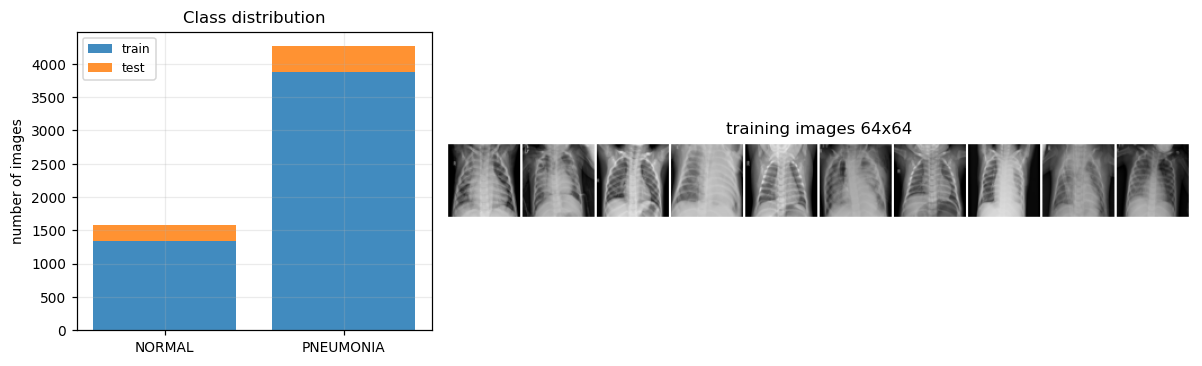

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2.1]})

ax = axes[0]
classes = ["NORMAL", "PNEUMONIA"]
bottom = np.zeros(len(classes))
for split, color in zip(("train", "test"), ("tab:blue", "tab:orange")):
    values = split_table.set_index("split").loc[split, classes].to_numpy(dtype=float)
    ax.bar(classes, values, bottom=bottom, label=split, color=color, alpha=0.85)
    bottom += values
ax.set_ylabel("number of images")
ax.set_title("Class distribution")
ax.legend(fontsize=8)

batch = next(iter(train_loader))[0][:10]
grid = vutils.make_grid(batch, nrow=10, padding=2, pad_value=1.0)
axes[1].imshow(grid.permute(1, 2, 0).squeeze(-1))
axes[1].axis("off")
axes[1].set_title(f"training images {cfg.image_size}x{cfg.image_size}")
axes[1].grid(False)

fig.tight_layout()
save_fig(fig, "dataset_overview")
plt.show()


## 3. Model

### 3.1 Formulation

The VAE models each image $x \in [0,1]^{1\times 64\times 64}$ through a diagonal Gaussian posterior and a
factorised Bernoulli likelihood:

$$
q_\phi(z\mid x)=\mathcal{N}\!\left(\mu_\phi(x),\ \operatorname{diag}\!\left(\sigma_\phi^2(x)\right)\right),
\qquad
p_\theta(x\mid z)=\prod_{i=1}^{D}\operatorname{Bern}\!\left(x_i;\ \pi_{\theta,i}(z)\right),
\qquad
p(z)=\mathcal{N}(0, I)
$$

The training objective is the $\beta$-weighted negative ELBO per image (in nats):

$$
\mathcal{L}(\theta,\phi;x)=
\underbrace{\mathbb{E}_{q_\phi(z\mid x)}\!\left[-\log p_\theta(x\mid z)\right]}_{\text{reconstruction (BCE)}}
\;+\;\beta\,
\underbrace{D_{\mathrm{KL}}\!\left(q_\phi(z\mid x)\,\big\|\,\mathcal{N}(0,I)\right)}_{\text{closed form}}
$$

$$
D_{\mathrm{KL}}=-\tfrac12\sum_{j=1}^{d}\left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right),
\qquad
z=\mu_\phi(x)+\sigma_\phi(x)\odot\epsilon,\quad \epsilon\sim\mathcal{N}(0,I)
$$

`reduction="sum"` is used for the BCE and then divided by the batch size, so both terms are *per image* and directly
comparable in nats; $\beta$ is annealed linearly from 0 to `cfg.beta` over the first `kl_warmup_epochs` epochs (KL warm-up),
which prevents the well-known posterior collapse in the first epochs.

### 3.2 Architecture

Symmetric convolutional VAE, `n_stages = log2(image_size) - 2` (4 stages for 64×64 → 4×4 feature map):

| part | layer | output shape |
|---|---|---|
| encoder | `Conv2d(1→32, k4 s2 p1) + BN + LeakyReLU(0.2)` | 32×32×32 |
| | `Conv2d(32→64, k4 s2 p1) + BN + LeakyReLU(0.2)` | 64×16×16 |
| | `Conv2d(64→128, k4 s2 p1) + BN + LeakyReLU(0.2)` | 128×8×8 |
| | `Conv2d(128→256, k4 s2 p1) + BN + LeakyReLU(0.2)` | 256×4×4 |
| | flatten → `Linear(4096→128)` ×2 | $\mu$, $\log\sigma^2$ ∈ ℝ¹²⁸ |
| decoder | `Linear(128→4096)` → reshape | 256×4×4 |
| | `ConvTranspose2d(256→128, k4 s2 p1) + BN + ReLU` | 128×8×8 |
| | `ConvTranspose2d(128→64, k4 s2 p1) + BN + ReLU` | 64×16×16 |
| | `ConvTranspose2d(64→32, k4 s2 p1) + BN + ReLU` | 32×32×32 |
| | `ConvTranspose2d(32→1, k4 s2 p1) + Sigmoid` | 1×64×64 |

Batch-norm on the last encoder block and the first decoder block is omitted (standard DCGAN-style VAE practice), and all
convolutional layers are bias-free because batch-norm follows them.


In [10]:
class Encoder(nn.Module):
    """q_phi(z|x): conv stack -> (mu, logvar)."""

    def __init__(self, image_size: int, in_channels: int, base_channels: int, latent_dim: int):
        super().__init__()
        self.n_stages = int(math.log2(image_size)) - 2
        channels = [min(base_channels * 2**i, 512) for i in range(self.n_stages)]

        blocks, prev = [], in_channels
        for ch in channels:
            blocks += [
                nn.Conv2d(prev, ch, kernel_size=4, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(ch),
                nn.LeakyReLU(0.2, inplace=True),
            ]
            prev = ch
        self.blocks = nn.Sequential(*blocks)

        self.feat_size = image_size // (2**self.n_stages)
        self.flat_dim = channels[-1] * self.feat_size * self.feat_size
        self.fc_mu = nn.Linear(self.flat_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flat_dim, latent_dim)

    def forward(self, x: torch.Tensor):
        h = self.blocks(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)


class Decoder(nn.Module):
    """p_theta(x|z): z -> transposed-conv stack -> Sigmoid in [0, 1]."""

    def __init__(self, image_size: int, out_channels: int, base_channels: int, latent_dim: int):
        super().__init__()
        n_stages = int(math.log2(image_size)) - 2
        channels = [min(base_channels * 2**i, 512) for i in range(n_stages)]
        self.feat_size = image_size // (2**n_stages)
        self.init_channels = channels[-1]

        self.fc = nn.Linear(latent_dim, self.init_channels * self.feat_size * self.feat_size)

        blocks, prev = [], self.init_channels
        for ch in reversed(channels[:-1]):
            blocks += [
                nn.ConvTranspose2d(prev, ch, kernel_size=4, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(ch),
                nn.ReLU(inplace=True),
            ]
            prev = ch
        blocks += [nn.ConvTranspose2d(prev, out_channels, kernel_size=4, stride=2, padding=1)]
        self.blocks = nn.Sequential(*blocks)

    def forward(self, z: torch.Tensor):
        h = self.fc(z).view(-1, self.init_channels, self.feat_size, self.feat_size)
        return torch.sigmoid(self.blocks(h))


class VAE(nn.Module):
    def __init__(self, image_size: int = 64, in_channels: int = 1, base_channels: int = 32, latent_dim: int = 128):
        super().__init__()
        self.latent_dim = latent_dim
        self.image_size = image_size
        self.encoder = Encoder(image_size, in_channels, base_channels, latent_dim)
        self.decoder = Decoder(image_size, in_channels, base_channels, latent_dim)

    @staticmethod
    def reparameterize(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x: torch.Tensor):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

    @torch.no_grad()
    def sample(self, n: int, device=DEVICE) -> torch.Tensor:
        """Sample n images from the prior: z ~ N(0, I) -> decoder."""
        was_training = self.training
        self.eval()
        z = torch.randn(n, self.latent_dim, device=device)
        images = self.decoder(z)
        self.train(was_training)
        return images

    @torch.no_grad()
    def reconstruct(self, x: torch.Tensor) -> torch.Tensor:
        """Deterministic reconstruction using the posterior mean."""
        was_training = self.training
        self.eval()
        mu, _ = self.encoder(x)
        images = self.decoder(mu)
        self.train(was_training)
        return images


In [11]:
model = VAE(
    image_size=cfg.image_size,
    in_channels=cfg.in_channels,
    base_channels=cfg.base_channels,
    latent_dim=cfg.latent_dim,
).to(DEVICE)


def n_params(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


with torch.no_grad():
    probe = torch.rand(2, cfg.in_channels, cfg.image_size, cfg.image_size, device=DEVICE)
    recon_probe, mu_probe, logvar_probe = model(probe)

print(f"encoder parameters : {n_params(model.encoder):>10,}")
print(f"decoder parameters : {n_params(model.decoder):>10,}")
print(f"total parameters   : {n_params(model):>10,}")
print(f"forward shapes     : x{tuple(probe.shape)} -> recon{tuple(recon_probe.shape)}, mu{tuple(mu_probe.shape)}, logvar{tuple(logvar_probe.shape)}")
print(f"output range       : [{recon_probe.min():.3f}, {recon_probe.max():.3f}]")


encoder parameters :  1,738,432
decoder parameters :  1,217,473
total parameters   :  2,955,905
forward shapes     : x(2, 1, 64, 64) -> recon(2, 1, 64, 64), mu(2, 128), logvar(2, 128)
output range       : [0.004, 0.982]


### 3.3 Objective and KL schedule


In [12]:
def vae_loss(recon_x: torch.Tensor, x: torch.Tensor, mu: torch.Tensor, logvar: torch.Tensor, beta: float = 1.0):
    """Negative ELBO per image (nats). Returns (total, recon, kl)."""
    recon = F.binary_cross_entropy(recon_x, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1.0 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon + beta * kl, recon.detach(), kl.detach()


def beta_for_epoch(epoch: int) -> float:
    """Linear KL warm-up: 0 -> cfg.beta over the first `kl_warmup_epochs` epochs."""
    if cfg.kl_warmup_epochs <= 0:
        return cfg.beta
    return cfg.beta * min(1.0, epoch / cfg.kl_warmup_epochs)


### 3.4 Device check and run-time estimate

Before launching the 50-epoch run, a three-iteration benchmark on the real architecture measures the cost of one
optimisation step on the selected device. On Apple Silicon this cell is the quickest way to confirm that MPS is actually
being used and to sanity-check the expected duration (a forward/backward pass of ~0.16 M parameters at 64×64).


In [13]:
def benchmark_device(device: torch.device, n_iter: int = 3) -> float:
    """Seconds per training iteration for the configured VAE on `device`."""
    probe = VAE(cfg.image_size, cfg.in_channels, cfg.base_channels, cfg.latent_dim).to(device)
    opt = torch.optim.Adam(probe.parameters(), lr=cfg.lr)
    x = torch.rand(cfg.batch_size, cfg.in_channels, cfg.image_size, cfg.image_size, device=device)

    def _one_step():
        opt.zero_grad(set_to_none=True)
        recon_x, mu, logvar = probe(x)
        loss, _, _ = vae_loss(recon_x, x, mu, logvar, beta=1.0)
        loss.backward()
        opt.step()

    def _sync():
        if device.type == "cuda":
            torch.cuda.synchronize()
        elif device.type == "mps":
            torch.mps.synchronize()

    for _ in range(n_iter):      # warm-up: MPS compiles kernels lazily on first use
        _one_step()
    _sync()

    t0 = time.perf_counter()
    for _ in range(n_iter):
        _one_step()
    _sync()
    elapsed = (time.perf_counter() - t0) / n_iter

    del probe, opt, x
    if device.type == "mps":
        torch.mps.empty_cache()
    return elapsed


try:
    sec_per_iter = benchmark_device(DEVICE)
    # the actual number of iterations per epoch is printed by the dataloader cell (§2.2)
    try:
        iters_per_epoch = len(train_loader)
    except NameError:            # §3.4 executed before §2.2
        iters_per_epoch = 4694 // cfg.batch_size
    print(
        f"{DEVICE.type}: {sec_per_iter * 1000:.0f} ms / iteration "
        f"-> ~{sec_per_iter * iters_per_epoch / 60:.1f} min / epoch "
        f"-> ~{sec_per_iter * iters_per_epoch * cfg.epochs / 60:.0f} min for {cfg.epochs} epochs (training only)"
    )
except Exception as exc:   # e.g. a convolution kernel missing on MPS
    print(f"device benchmark failed on {DEVICE.type}: {exc}")
    print("-> set cfg.device = 'cpu' in the configuration cell (§1.3) and re-run")
    sec_per_iter = float("nan")


mps: 13 ms / iteration -> ~0.0 min / epoch -> ~1 min for 50 epochs (training only)


## 4. Evaluation metrics: Inception Score and FID

Both metrics are the `pytorch-ignite` implementations used in the reference notebook
(<https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/>):

```python
from ignite.metrics import FID, InceptionScore

fid_metric = FID(device=..., feature_extractor=...)
is_metric  = InceptionScore(device=..., output_transform=lambda x: x[0])
```

- **Inception Score** — $\exp\!\big(\mathbb{E}_x[D_{KL}(p(y|x)\,\|\,p(y))]\big)$: a sample should be confidently
  classified (low entropy of $p(y|x)$) while the marginal $p(y)$ should be broad (high entropy). **Higher is better.**
- **Frechet Inception Distance** — $|\mu_r-\mu_g|^2+\operatorname{Tr}(\Sigma_r+\Sigma_g-2(\Sigma_r\Sigma_g)^{1/2})$ between
  the feature distributions of real and generated images. **Lower is better.**

Three adaptations are needed for this dataset:

1. **Grayscale → RGB.** InceptionV3 requires 3 channels, so the single channel is replicated three times.
2. **Resolution.** InceptionV3 requires at least 299×299. As discussed in the reference notebook and in Parmar et al.
   (2022), resizing is done with **PIL bilinear** (anti-aliased) instead of `torch.nn.functional.interpolate`, because
   aliasing strongly biases FID. Real images are resized from the original JPEGs (see §2.2).
3. **Feature choice.** FID uses the 2048-d global-pool features of InceptionV3 (the definition of the original FID paper);
   IS uses the 1000-d softmax probabilities. Both are obtained from `ignite.metrics.gan.utils.InceptionModel`, the same
   ImageNet-pretrained network the reference notebook uses.

`output_transform=lambda x: x[0]` is needed because the evaluation engine returns `(fake, real)` while `InceptionScore`
only consumes the generated images. In `FID`, the first argument of `update` accumulates the *generated* features and the
second one the *real* features, hence the `(fake, real)` ordering below.

**Device split.** The two `InceptionModel` extractors run on `EXTRACTOR_DEVICE` (CUDA → MPS → CPU, with a one-image probe
to confirm kernel support), while `FID`/`InceptionScore` accumulate in `float64` on `METRIC_DEVICE` (CPU when only MPS is
present). This needs a small wrapper, because `_BaseInceptionMetric.__init__` unconditionally calls
`feature_extractor.to(metric_device)` — which would drag the 27 M-parameter network back to CPU. `DeviceLockedExtractor`
ignores `.to(...)`, moves each incoming batch to the network's own device, and returns `float32` CPU features that ignite
then casts to `float64`. Net effect: the expensive 299×299 convolutions run on the GPU, the cheap matrix accumulation on
the CPU.


In [14]:
class DeviceLockedExtractor(nn.Module):
    """Keep an InceptionV3 on its own device, whatever ignite asks for.

    `ignite.metrics.gan.utils._BaseInceptionMetric.__init__` calls
    `feature_extractor.to(metric_device)`, which would drag the 27M-parameter network back to the
    metric device (cpu). FID/IS must accumulate on cpu because MPS has no float64, but the
    299x299 convolutions are far cheaper on the GPU, so this wrapper
      * ignores `.to(...)`/`.cuda()`/`.cpu()` (the network stays where it was built),
      * moves each incoming batch to the network's device,
      * returns plain `float32` cpu features, which ignite then casts to `float64`.
    """

    def __init__(self, model: nn.Module, device: torch.device):
        super().__init__()
        self.model = model
        self.extractor_device = torch.device(device)

    def to(self, *args, **kwargs):
        return self

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            out = self.model(x.to(self.extractor_device))
        return out.float().cpu()


def best_accelerator() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def build_extractor(return_features: bool, device: torch.device) -> DeviceLockedExtractor:
    return DeviceLockedExtractor(InceptionModel(return_features=return_features, device=device), device)


def extractor_works(extractor: DeviceLockedExtractor) -> bool:
    """One-image forward pass, to catch a conv kernel that MPS does not implement."""
    if extractor.extractor_device.type == "cpu":
        return True
    try:
        extractor(torch.rand(1, 3, 299, 299))
        return True
    except Exception as exc:
        print(f"InceptionV3 on {extractor.extractor_device.type} failed ({type(exc).__name__}: {exc}) -> falling back to cpu")
        return False


EXTRACTOR_DEVICE = best_accelerator()
feature_extractor = build_extractor(return_features=True, device=EXTRACTOR_DEVICE)
if not extractor_works(feature_extractor):
    EXTRACTOR_DEVICE = torch.device("cpu")
    feature_extractor = build_extractor(return_features=True, device=EXTRACTOR_DEVICE)

prob_extractor = build_extractor(return_features=False, device=EXTRACTOR_DEVICE)

fid_metric = FID(num_features=cfg.fid_num_features, feature_extractor=feature_extractor, device=METRIC_DEVICE)
is_metric = InceptionScore(
    num_features=1000,
    feature_extractor=prob_extractor,
    device=METRIC_DEVICE,
    output_transform=lambda x: x[0],   # the engine returns (fake, real); IS only needs (fake)
)

print(f"InceptionV3 forward pass  : {EXTRACTOR_DEVICE}")
print(f"FID/IS float64 statistics : {METRIC_DEVICE}")


InceptionV3 forward pass  : mps
FID/IS float64 statistics : cpu


In [15]:
def to_inception(batch: torch.Tensor) -> torch.Tensor:
    """[N, 1, H, W] in [0, 1] -> [N, 3, 299, 299] using PIL bilinear resampling.

    The batch is always brought to CPU first: `ToPILImage` needs a CPU tensor, and the resulting
    uint8 round-trip is what the reference notebook does as well. Ignite then moves the tensor to
    the extractor device internally (`_extract_features`), so the device is not handled here.
    PIL is used instead of `torch.nn.functional.interpolate` to get anti-aliased resizing,
    as recommended by the PyTorch-Ignite reference notebook (Parmar et al., 2022).
    """
    out = []
    for img in batch.detach().float().cpu():
        pil_img = T.ToPILImage()(img)
        pil_img = pil_img.resize((299, 299), Image.BILINEAR)
        tensor = T.ToTensor()(pil_img)
        if tensor.shape[0] == 1:
            tensor = tensor.repeat(3, 1, 1)   # grayscale -> RGB for InceptionV3
        out.append(tensor)
    return torch.stack(out)


In [16]:
def evaluation_step(engine, batch):
    """One evaluation step: (real 3x299x299, generated 3x299x299)."""
    real = batch[0]                                   # already 3 x 299 x 299 from inception_transform
    was_training = model.training
    model.eval()
    with torch.no_grad():
        # match the real batch size exactly, otherwise FID.update rejects the pair
        fake = model.decoder(torch.randn(real.size(0), model.latent_dim, device=DEVICE))
        fake = to_inception(fake)
    model.train(was_training)   # `evaluator.run` is called from a trainer handler: restore the mode
    return fake, real


evaluator = Engine(evaluation_step)
fid_metric.attach(evaluator, "fid")
is_metric.attach(evaluator, "is")


## 5. Training

| choice | value | rationale |
|---|---|---|
| optimiser | Adam, lr `1e-3` → `1e-5` (cosine) | standard for VAEs; cosine decay stabilises the last epochs |
| batch size | 64 | fits comfortably on CPU/MPS |
| epochs | 50 | ~73 iterations per epoch |
| reconstruction | BCE (sum / batch) | correct likelihood for `[0, 1]` pixels with a sigmoid decoder |
| KL weight | $\beta$: 0 → 1 over 10 epochs | avoids posterior collapse early in training |
| gradient clipping | 5.0 (global norm) | guards against occasional loss spikes |
| initialisation | PyTorch default | BN + LeakyReLU make DCGAN-style init unnecessary |

### 5.1 Engines and handlers

`pytorch-ignite` separates the *process function* (one optimisation step) from the *engine* (the loop) and from
*handlers* (everything that happens at `STARTED` / `ITERATION_COMPLETED` / `EPOCH_COMPLETED`). The handlers below

- store per-iteration and per-epoch losses,
- run the validation ELBO every epoch,
- run the IS/FID `evaluator` every `eval_every` epochs (and always on the last one),
- keep `last.pt` and the best-FID `best.pt` checkpoints,
- dump a grid of 64 prior samples every `sample_every` epochs for the qualitative progress figure.


In [17]:
optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs, eta_min=cfg.lr_min)

CKPT_DIR = Path(cfg.ckpt_dir)
CKPT_DIR.mkdir(parents=True, exist_ok=True)


def save_checkpoint(name: str, epoch: int, metrics: dict | None = None) -> Path:
    path = CKPT_DIR / name
    torch.save(
        {
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "config": asdict(cfg),
            "metrics": metrics or {},
        },
        path,
    )
    return path


def load_vae(path, device: torch.device | None = None) -> VAE:
    """Rebuild a VAE from a checkpoint written by `save_checkpoint` and move it to `device`."""
    device = device or DEVICE
    ckpt = torch.load(path, map_location=device, weights_only=False)
    saved = Config(**ckpt["config"])
    vae = VAE(
        image_size=saved.image_size,
        in_channels=saved.in_channels,
        base_channels=saved.base_channels,
        latent_dim=saved.latent_dim,
    ).to(device)
    vae.load_state_dict(ckpt["model"])
    vae.eval()
    return vae


def training_step(engine, batch):
    model.train()
    x = batch[0].to(DEVICE, non_blocking=True)
    beta = beta_for_epoch(engine.state.epoch)

    optimizer.zero_grad(set_to_none=True)
    recon_x, mu, logvar = model(x)
    loss, recon_loss, kl_loss = vae_loss(recon_x, x, mu, logvar, beta=beta)
    loss.backward()
    if cfg.grad_clip > 0:
        nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
    optimizer.step()

    return {"loss": loss.item(), "recon": recon_loss.item(), "kl": kl_loss.item(), "beta": beta}


@torch.no_grad()
def validation_step(engine, batch):
    model.eval()
    x = batch[0].to(DEVICE, non_blocking=True)
    recon_x, mu, logvar = model(x)
    loss, recon_loss, kl_loss = vae_loss(recon_x, x, mu, logvar, beta=cfg.beta)
    return {"loss": loss.item(), "recon": recon_loss.item(), "kl": kl_loss.item()}


trainer = Engine(training_step)
validator = Engine(validation_step)

for metric_name in ("loss", "recon", "kl"):
    RunningAverage(output_transform=lambda out, n=metric_name: out[n]).attach(trainer, metric_name)
    RunningAverage(output_transform=lambda out, n=metric_name: out[n]).attach(validator, metric_name)

ProgressBar(persist=False).attach(trainer, metric_names=["loss", "recon", "kl"])

# ---------------------------------------------------------------- bookkeeping
iter_log = {"loss": [], "recon": [], "kl": [], "beta": []}
history = {
    "epoch": [],
    "train_loss": [],
    "train_recon": [],
    "train_kl": [],
    "val_loss": [],
    "val_recon": [],
    "val_kl": [],
    "beta": [],
    "lr": [],
    "eval_epoch": [],
    "is": [],
    "fid": [],
}
best = {"fid": float("inf"), "epoch": None}


@trainer.on(Events.ITERATION_COMPLETED)
def store_iteration(engine):
    out = engine.state.output
    for key in iter_log:
        iter_log[key].append(out[key])


@trainer.on(Events.EPOCH_COMPLETED)
def log_epoch(engine):
    val_metrics = validator.run(val_loader, max_epochs=1).metrics
    m = engine.state.metrics

    history["epoch"].append(engine.state.epoch)
    history["train_loss"].append(m["loss"])
    history["train_recon"].append(m["recon"])
    history["train_kl"].append(m["kl"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_recon"].append(val_metrics["recon"])
    history["val_kl"].append(val_metrics["kl"])
    history["beta"].append(beta_for_epoch(engine.state.epoch))
    history["lr"].append(optimizer.param_groups[0]["lr"])

    print(
        f"[epoch {engine.state.epoch:03d}/{cfg.epochs}] "
        f"train {m['loss']:.2f} (recon {m['recon']:.2f} + beta*KL {m['kl']:.2f}, beta={history['beta'][-1]:.2f}) | "
        f"val {val_metrics['loss']:.2f} | lr {history['lr'][-1]:.2e}"
    )


@trainer.on(Events.EPOCH_COMPLETED)
def step_scheduler(engine):
    scheduler.step()


@trainer.on(Events.EPOCH_COMPLETED)
def evaluate_fid_is(engine):
    epoch = engine.state.epoch
    if epoch % cfg.eval_every != 0 and epoch != cfg.epochs:
        return
    t0 = time.time()
    scores = evaluator.run(real_eval_loader, max_epochs=1).metrics

    history["eval_epoch"].append(epoch)
    history["is"].append(scores["is"])
    history["fid"].append(scores["fid"])

    improved = scores["fid"] < best["fid"]
    if improved:
        best.update(fid=scores["fid"], epoch=epoch)
        save_checkpoint("best.pt", epoch, {"is": scores["is"], "fid": scores["fid"]})

    print(
        f"[epoch {epoch:03d}] IS = {scores['is']:.3f} (higher is better) | "
        f"FID = {scores['fid']:.3f} (lower is better) | {time.time() - t0:.1f}s"
        + ("  <- best so far, saved best.pt" if improved else "")
    )


@trainer.on(Events.EPOCH_COMPLETED)
def checkpoint_last(engine):
    save_checkpoint("last.pt", engine.state.epoch, {"is": None, "fid": best["fid"]})


@trainer.on(Events.EPOCH_COMPLETED(every=cfg.sample_every))
def store_sample_grid(engine):
    samples = model.sample(64, DEVICE).cpu()
    grid = vutils.make_grid(samples, nrow=8, padding=2)
    vutils.save_image(grid, SAMPLE_DIR / f"epoch_{engine.state.epoch:03d}.png")
    if DEVICE.type == "mps":
        torch.mps.empty_cache()


print(f"ready: {cfg.epochs} epochs x {len(train_loader)} iterations")


ready: 50 epochs x 73 iterations


/opt/anaconda3/envs/ml/lib/python3.11/site-packages/ignite/handlers/tqdm_logger.py:130: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


In [18]:
t0 = time.time()
trainer.run(train_loader, max_epochs=cfg.epochs)
elapsed = (time.time() - t0) / 60
print(f"\ntraining finished in {elapsed:.1f} min | best FID {best['fid']:.3f} @ epoch {best['epoch']}")


[epoch 001/50] train 2728.97 (recon 2717.73 + beta*KL 112.38, beta=0.10) | val 2494.49 | lr 1.00e-03


[epoch 002/50] train 2483.61 (recon 2466.53 + beta*KL 98.25, beta=0.20) | val 2465.13 | lr 9.99e-04


[epoch 003/50] train 2425.99 (recon 2405.06 + beta*KL 79.22, beta=0.30) | val 2431.15 | lr 9.96e-04


[epoch 004/50] train 2410.45 (recon 2387.57 + beta*KL 63.35, beta=0.40) | val 2420.45 | lr 9.91e-04


[epoch 005/50] train 2407.91 (recon 2383.80 + beta*KL 52.26, beta=0.50) | val 2402.02 | lr 9.84e-04
[epoch 005] IS = 1.283 (higher is better) | FID = 348.912 (lower is better) | 17.2s  <- best so far, saved best.pt


...

[epoch 046/50] train 2389.04 (recon 2364.95 + beta*KL 24.10, beta=1.00) | val 2363.03 | lr 3.42e-05


[epoch 047/50] train 2389.18 (recon 2365.05 + beta*KL 24.13, beta=1.00) | val 2363.03 | lr 2.56e-05


[epoch 048/50] train 2390.77 (recon 2366.68 + beta*KL 24.09, beta=1.00) | val 2362.67 | lr 1.88e-05


[epoch 049/50] train 2389.49 (recon 2365.47 + beta*KL 24.03, beta=1.00) | val 2362.41 | lr 1.39e-05


[epoch 050/50] train 2388.75 (recon 2364.67 + beta*KL 24.08, beta=1.00) | val 2362.54 | lr 1.10e-05
[epoch 050] IS = 1.626 (higher is better) | FID = 344.392 (lower is better) | 14.0s

training finished in 9.6 min | best FID 341.493 @ epoch 45


## 6. Results

### 6.1 Loss curves

The left panel shows the per-iteration training loss (light: raw, dark: exponential moving average) together with the
validation ELBO, plotted on the same axis by mapping each epoch to the iteration index where it ends. The right panel
separates the two terms of the objective: the reconstruction term should decrease monotonically, while the KL term first
grows (the encoder starts using the latent space, helped by the KL warm-up) and then stabilises — a KL that collapses to
~0 would indicate posterior collapse.


saved figure -> results/figures/loss_curves.png


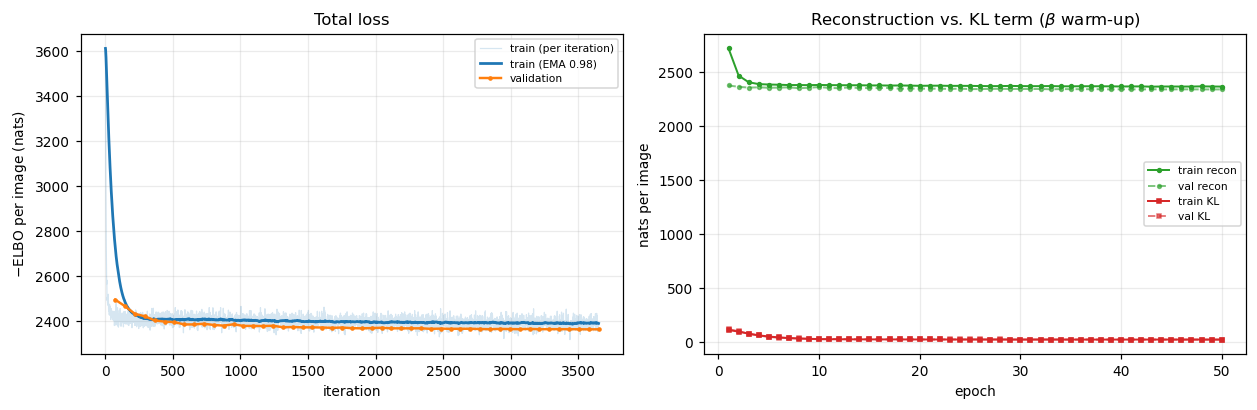

In [19]:
def ema(values, weight: float = 0.98):
    if not values:
        return []
    out = [values[0]]
    for v in values[1:]:
        out.append(out[-1] * weight + (1.0 - weight) * v)
    return out


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

ax = axes[0]
iters = np.arange(1, len(iter_log["loss"]) + 1)
ax.plot(iters, iter_log["loss"], color="tab:blue", alpha=0.18, lw=0.8, label="train (per iteration)")
ax.plot(iters, ema(iter_log["loss"], 0.98), color="tab:blue", lw=1.8, label="train (EMA 0.98)")
ax.plot(
    np.arange(1, len(history["val_loss"]) + 1) * len(train_loader),
    history["val_loss"],
    color="tab:orange",
    lw=1.6,
    marker=".",
    ms=4,
    label="validation",
)
ax.set_xlabel("iteration")
ax.set_ylabel(r"$-$ELBO per image (nats)")
ax.set_title("Total loss")
ax.legend(fontsize=7)

ax = axes[1]
epochs = history["epoch"]
ax.plot(epochs, history["train_recon"], "o-", ms=2.5, lw=1.3, color="tab:green", label="train recon")
ax.plot(epochs, history["val_recon"], "o--", ms=2.5, lw=1.3, color="tab:green", alpha=0.6, label="val recon")
ax.plot(epochs, history["train_kl"], "s-", ms=2.5, lw=1.3, color="tab:red", label="train KL")
ax.plot(epochs, history["val_kl"], "s--", ms=2.5, lw=1.3, color="tab:red", alpha=0.6, label="val KL")
ax.set_xlabel("epoch")
ax.set_ylabel("nats per image")
ax.set_title(r"Reconstruction vs. KL term ($\beta$ warm-up)")
ax.legend(fontsize=7)

fig.tight_layout()
save_fig(fig, "loss_curves")
plt.show()


### 6.2 Inception Score and FID during training

Both axes are kept on the same scale convention as the reference notebook: **IS higher is better**, **FID lower is
better**. Because the VAE is trained with a reconstruction objective rather than an adversarial one, the metrics improve
smoothly and then plateau instead of oscillating — a typical signature of blurry but stable samples.


saved figure -> results/figures/fid_is_curve.png


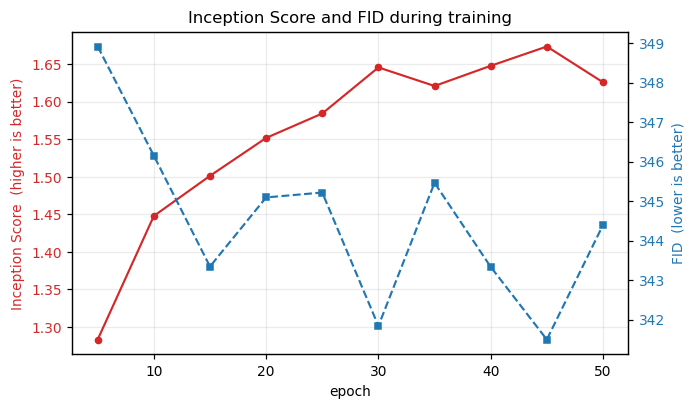

,epoch,IS,FID
0,5,1.283,348.912
1,10,1.448,346.148
2,15,1.501,343.342
3,20,1.552,345.091
4,25,1.584,345.215
5,30,1.646,341.837
6,35,1.621,345.461
7,40,1.648,343.332
8,45,1.673,341.493
9,50,1.626,344.392


In [20]:
fig, ax1 = plt.subplots(figsize=(6.4, 3.8))

ax1.set_title("Inception Score and FID during training")
ax1.set_xlabel("epoch")
ax1.set_ylabel("Inception Score  (higher is better)", color="tab:red")
ax1.plot(history["eval_epoch"], history["is"], "o-", color="tab:red", ms=4, lw=1.4, label="IS")
ax1.tick_params(axis="y", labelcolor="tab:red")

ax2 = ax1.twinx()
ax2.grid(False)
ax2.set_ylabel("FID  (lower is better)", color="tab:blue")
ax2.plot(history["eval_epoch"], history["fid"], "s--", color="tab:blue", ms=4, lw=1.4, label="FID")
ax2.tick_params(axis="y", labelcolor="tab:blue")

fig.tight_layout()
save_fig(fig, "fid_is_curve")
plt.show()

pd.DataFrame({"epoch": history["eval_epoch"], "IS": np.round(history["is"], 3), "FID": np.round(history["fid"], 3)})


## 7. Generated images

### 7.1 Samples from the prior

64 images generated from $z \sim \mathcal{N}(0, I)$ with the best checkpoint. This is the grid that goes into the report.


loaded checkpoints/best.pt
saved -> results/figures/generated_samples.png


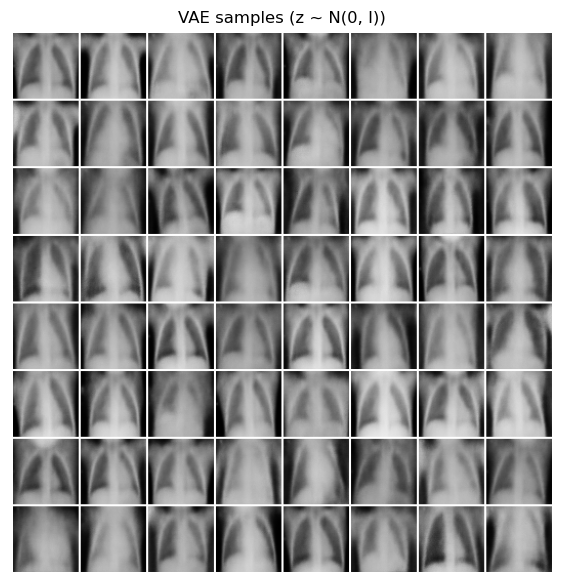

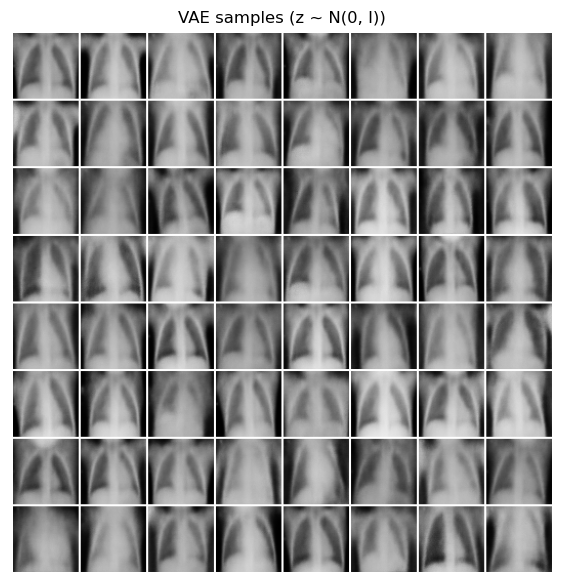

In [21]:
def show_grid(tensor: torch.Tensor, nrow: int = 8, title: str | None = None, path: Path | None = None, figsize=(6.4, 6.4)):
    """Display a batch [N, 1, H, W] (or [N, 3, H, W]) as a grid."""
    grid = vutils.make_grid(tensor, nrow=nrow, padding=2, pad_value=1.0)
    arr = grid.permute(1, 2, 0).numpy()
    fig, ax = plt.subplots(figsize=figsize)
    if arr.shape[-1] == 1:
        ax.imshow(arr.squeeze(-1), cmap="gray", vmin=0, vmax=1)
    else:
        ax.imshow(arr)
    ax.axis("off")
    ax.grid(False)
    if title:
        ax.set_title(title)
    if path is not None:
        fig.savefig(path, dpi=150, bbox_inches="tight")
        print(f"saved -> {path}")
    plt.show()
    return fig


ckpt_path = CKPT_DIR / ("best.pt" if (CKPT_DIR / "best.pt").exists() else "last.pt")
best_model = load_vae(ckpt_path)
print(f"loaded {ckpt_path}")

samples = best_model.sample(64, DEVICE).cpu()
show_grid(samples, nrow=8, title="VAE samples (z ~ N(0, I))", path=FIG_DIR / "generated_samples.png")


### 7.2 Latent interpolation

Two validation images are encoded to their posterior means and the latent code is linearly interpolated between them.
A well-trained VAE produces a smooth transition — a qualitative sign that the latent space is regularised and that the
KL term did not collapse.


saved -> results/figures/latent_interpolation.png


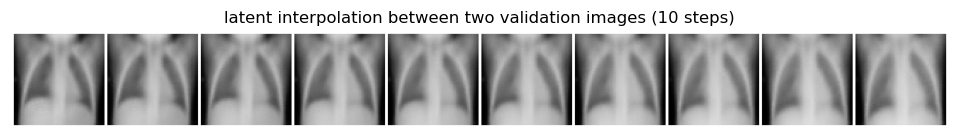

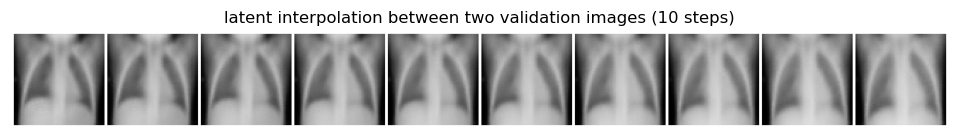

In [22]:
imgs, _ = next(iter(val_loader))
imgs = imgs[:2].to(DEVICE)

with torch.no_grad():
    mu_pair, _ = best_model.encoder(imgs)

steps = 10
alphas = torch.linspace(0.0, 1.0, steps, device=DEVICE).view(-1, 1)
z_interp = (1 - alphas) * mu_pair[0] + alphas * mu_pair[1]

with torch.no_grad():
    interp = best_model.decoder(z_interp).cpu()

show_grid(
    interp,
    nrow=steps,
    title=f"latent interpolation between two validation images ({steps} steps)",
    path=FIG_DIR / "latent_interpolation.png",
    figsize=(11, 1.6),
)


### 7.3 Reconstructions

Top row: real validation images. Bottom row: the same images after encoding to $\mu_\phi(x)$ and decoding. The
reconstruction error measured this way is a measure of how much information the 128-d latent code keeps — the expected
signature of a VAE is slightly blurred but anatomically consistent reconstructions.


saved figure -> results/figures/reconstructions.png


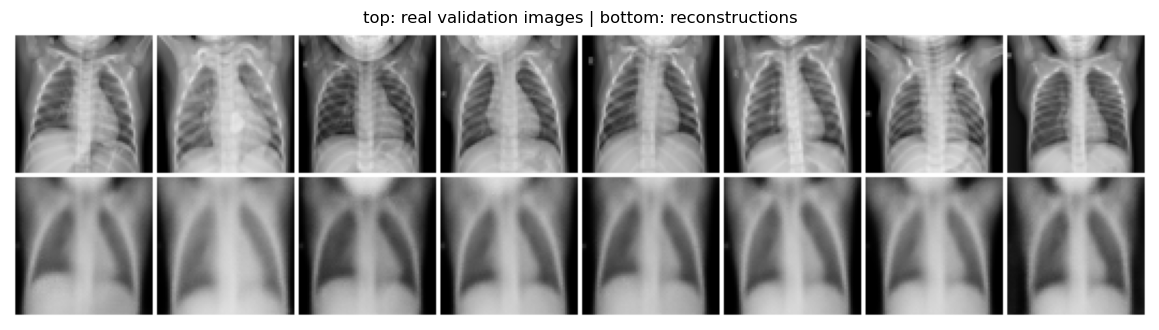

reconstruction MSE on 8 validation images: 0.00337


In [23]:
imgs, _ = next(iter(val_loader))
imgs = imgs[:8].to(DEVICE)

with torch.no_grad():
    recon = best_model.reconstruct(imgs).cpu()

grid = vutils.make_grid(torch.cat([imgs.cpu(), recon], dim=0), nrow=8, padding=2, pad_value=1.0)
fig, ax = plt.subplots(figsize=(11, 3.0))
ax.imshow(grid.permute(1, 2, 0).squeeze(-1), cmap="gray", vmin=0, vmax=1)
ax.set_title("top: real validation images | bottom: reconstructions")
ax.axis("off")
ax.grid(False)
fig.tight_layout()
save_fig(fig, "reconstructions")
plt.show()

with torch.no_grad():
    mse = F.mse_loss(best_model.reconstruct(imgs), imgs).item()
print(f"reconstruction MSE on 8 validation images: {mse:.5f}")


## 8. Reference metrics

IS and FID are only meaningful relative to a baseline computed on the *real* data. Two references are reported:

1. **IS of the real test images** — an upper reference: real radiographs are confidently classified by InceptionV3, so a
   generator can never reach this value.
2. **FID between two disjoint halves of the real test set** — a lower reference: two samples of the same distribution
   should give a small FID (it is not exactly 0 because both halves are finite, 256 images each).

The same code path (`compute_fid_is`) is then used to score 512 samples of the best checkpoint, so the numbers are directly
comparable.


In [24]:
def compute_fid_is(vae: VAE, loader, max_batches: int | None = None):
    """Score a VAE with FID/IS against the real reference loader (reuses the loaded extractors)."""
    vae.eval()
    fid = FID(num_features=cfg.fid_num_features, feature_extractor=feature_extractor, device=METRIC_DEVICE)
    inception = InceptionScore(num_features=1000, feature_extractor=prob_extractor, device=METRIC_DEVICE)

    for i, batch in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        real = batch[0]
        with torch.no_grad():   # generated images are decoded on the training device
            fake_z = torch.randn(real.size(0), vae.latent_dim, device=DEVICE)
            fake = to_inception(vae.decoder(fake_z))
        fid.update((fake, real))
        inception.update(fake)

    return float(fid.compute()), float(inception.compute())


# ---- reference 1: IS of real images
is_real = InceptionScore(num_features=1000, feature_extractor=prob_extractor, device=METRIC_DEVICE)
real_loader_full = DataLoader(real_eval_subset, batch_size=cfg.eval_batch_size, shuffle=False, drop_last=False)
for batch in real_loader_full:
    is_real.update(batch[0])  # InceptionScore consumes images only
real_is = float(is_real.compute())

# ---- reference 2: FID between two disjoint halves of the real set
indices = list(range(len(real_eval_subset)))
half = (len(indices) // 2 // cfg.eval_batch_size) * cfg.eval_batch_size
loader_a = DataLoader(Subset(real_eval_subset, indices[:half]), batch_size=cfg.eval_batch_size, shuffle=False, drop_last=True)
loader_b = DataLoader(Subset(real_eval_subset, indices[half : 2 * half]), batch_size=cfg.eval_batch_size, shuffle=False, drop_last=True)

fid_real = FID(num_features=cfg.fid_num_features, feature_extractor=feature_extractor, device=METRIC_DEVICE)
for batch_a, batch_b in zip(loader_a, loader_b):
    fid_real.update((batch_a[0], batch_b[0]))  # FID consumes images only
real_fid = float(fid_real.compute())

# ---- our model, scored on exactly the same real reference set
final_fid, final_is = compute_fid_is(best_model, real_eval_loader)

print(f"VAE  (best epoch {best['epoch']:>2}) : IS = {final_is:.3f} | FID = {final_fid:.3f}")
print(f"real images (reference)    : IS = {real_is:.3f} | FID(real vs real) = {real_fid:.3f}")


VAE  (best epoch 45) : IS = 1.618 | FID = 343.511
real images (reference)    : IS = 2.289 | FID(real vs real) = 66.302


## 9. Export for the report

Everything the report needs is written to `results/`:

| file | content |
|---|---|
| `results/training_history.csv` | per-epoch train/validation loss, recon, KL, beta, lr |
| `results/fid_is_history.csv` | epoch, IS, FID |
| `results/metrics_summary.json` | final hyperparameters and metrics |
| `results/figures/*.png` | loss curves, IS/FID curve, samples, interpolation, reconstructions |
| `results/samples/epoch_XXX.png` | qualitative progress during training |
| `checkpoints/best.pt`, `checkpoints/last.pt` | model weights + config |


In [25]:
history_df = pd.DataFrame(
    {
        "epoch": history["epoch"],
        "train_loss": history["train_loss"],
        "train_recon": history["train_recon"],
        "train_kl": history["train_kl"],
        "val_loss": history["val_loss"],
        "val_recon": history["val_recon"],
        "val_kl": history["val_kl"],
        "beta": history["beta"],
        "lr": history["lr"],
    }
)
history_df.to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame({"epoch": history["eval_epoch"], "IS": history["is"], "FID": history["fid"]}).to_csv(
    OUT_DIR / "fid_is_history.csv", index=False
)

summary = {
    "config": asdict(cfg),
    "device": str(DEVICE),
    "metric_device": str(METRIC_DEVICE),
    "n_train": len(train_dataset),
    "n_val": len(val_dataset),
    "n_eval": len(real_eval_subset),
    "best_epoch": best["epoch"],
    "best_fid": best["fid"],
    "final_is": final_is,
    "final_fid": final_fid,
    "reference_is_real": real_is,
    "reference_fid_real_vs_real": real_fid,
    "training_minutes": elapsed,
}
with open(OUT_DIR / "metrics_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

pd.DataFrame(
    [
        {"model": "VAE (this work)", "IS (higher better)": round(final_is, 3), "FID (lower better)": round(final_fid, 3)},
        {"model": "real images (reference)", "IS (higher better)": round(real_is, 3), "FID (lower better)": round(real_fid, 3)},
    ]
)


,model,IS (higher better),FID (lower better)
0,VAE (this work),1.618,343.511
1,real images (reference),2.289,66.302


## 10. Report outline and limitations

### 10.1 What goes in the 2-page NeurIPS report

1. **Introduction** — motivation: generative models for medical imaging, why a VAE (stable training, explicit likelihood,
   smooth latent space) instead of a GAN for this dataset size.
2. **Method** — the ELBO above, the architecture table of §3.2, the Bernoulli likelihood.
3. **Experiments** — the hyperparameter table of §1.3, the splits of §2.1, the optimiser/schedules of §5.
4. **Results** — loss curves (§6.1), IS/FID curve and final numbers (§6.2, §8), generated samples (§7.1),
   interpolation (§7.2), reconstructions (§7.3).
5. **Discussion** — see below.

### 10.2 Limitations worth stating explicitly

- **Inception metrics on grayscale medical images.** IS and FID rely on an ImageNet classifier; chest radiographs are far
  from the ImageNet distribution, so both scores are dominated by texture/contrast statistics rather than by anatomical
  correctness. They are used here for comparability with the reference notebook, not as a clinical measure.
- **Blurriness.** The Gaussian-Bernoulli VAE optimises a pixel-wise likelihood, whose optimum is the conditional mean →
  samples are systematically smoother than real radiographs. A perceptual or adversarial reconstruction term would fix
  this at the cost of the clean likelihood interpretation.
- **Resolution.** 64×64 keeps the training budget reasonable, but fine structures (ribs, infiltrates) are lost. The same
  code runs at 128×128 by changing `Config.image_size`.
- **No class conditioning.** The VAE is unconditional; the label is not used. A conditional VAE (`cVAE`) would let us
  generate NORMAL or PNEUMONIA on demand — a natural extension.
- **Single seed.** All numbers come from one run ($\mathrm{seed}=42$); reporting mean ± std over 3 seeds would make the
  comparison between configurations statistically meaningful.


In [26]:
# --- Appendix: reuse the trained model without retraining ---
# vae = load_vae(CKPT_DIR / "best.pt")
# imgs = vae.sample(16, DEVICE)
# show_grid(imgs.cpu(), nrow=4, title="16 samples from the prior")
